# TODO : 
    - Calcule coeff propre (ratio to integer cap)
    - Model CRFB clean with noise / Finita Gain / Settling error
        - FFT + ramp + max SNR
    - Add Model CRFF
    - Understand diff bewteen CR & CI
    - Add compute cap size + spec for each INT
## Schematic :
    - Add single 2 diff with cap
    - Try with Vref = 800mV

In [54]:
# Active l'affichage des figures dans le notebook (backend inline).
# Sans cette ligne, matplotlib peut utiliser le backend 'agg' et
# aucune image ne s'affiche sous les cellules.
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

# Désactive le recadrage "tight" qui casse libpng quand un texte est hors limites
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

# DPI raisonnable et borné
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 100
from __future__ import division
from IPython.core.display import Image
from deltasigma import *
import warnings
warnings.filterwarnings('ignore')
# skip this, this is just to display nice tables.
from itertools import zip_longest
class Table(list):
    def _repr_html_(self):
        html = ["<table>"]
        for row in self:
            html.append("<tr>")
            for col in row:
                try:
                    float(col)
                    html.append("<td>%.3f</td>" % col)
                except(ValueError):
                    html.append("<td><b>%s</b></td>" % col)
            html.append("</tr>")
        html.append("</table>")
        return ''.join(html)
np.set_printoptions(suppress=True, precision=3)

In [55]:
from __future__ import print_function
import deltasigma as ds
print(ds.simulation_backends)

{'Cython': True, 'CPython': True}


# Delta Sigma modulator synthesis - example #1

## Set up the parameters

In [56]:
order = 2
osr = 30
nlev = 2
f0 = 0.
Hinf = 1.5
form = 'CIFF'
opt = 0
xlim = 0.5
Vdd = 1
Vref = 1


## Synthesize the NTF

In [57]:
ntf = synthesizeNTF(order, osr, opt, Hinf, f0)            # No Optimized zero placement
print("Synthesized a %d-order NTF, with roots:\n" % order)
print(" Zeros:\t\t\t Poles:")
for z, p in zip(ntf[0], ntf[1]):
    print("(%f, %fj)\t(%f, %fj)" % (np.real(z), np.imag(z), np.real(p), np.imag(p)))
print("")
print("The NTF transfer function has the following expression:\n")
print(pretty_lti(ntf))
print("")

Synthesized a 2-order NTF, with roots:

 Zeros:			 Poles:
(1.000000, 0.000000j)	(0.612574, -0.257432j)
(1.000000, 0.000000j)	(0.612574, 0.257432j)

The NTF transfer function has the following expression:

        (z - 1)^2        
-------------------------
 (z^2 - 1.225z + 0.4415) 



### Graphical inspection of the synthesized singularities

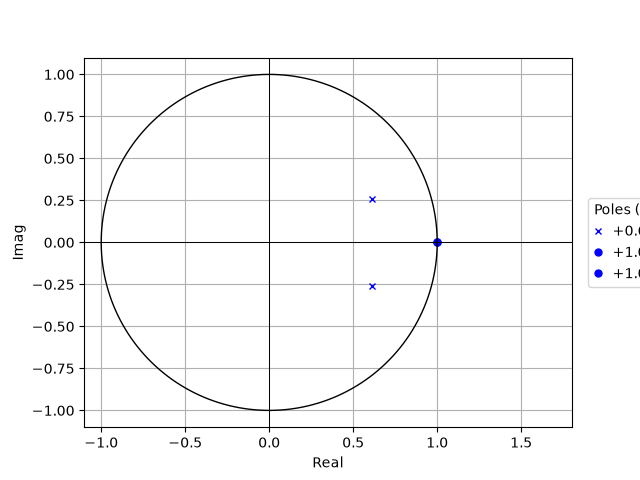

In [58]:
plt.xlim((-1.1, 1.5))
plt.ylim((-1.1, 1.1))
plotPZ(ntf, showlist=True)

## Realize the NTF with the CRFB topology and create the ABCD representation

In [59]:
a, g, b, c = realizeNTF(ntf, form)
#g = 0 #no resonator
# b = np.hstack(( # Use a single feed-in for the input
#                 np.atleast_1d(b[0]),
#                 np.zeros((b.shape[0] - 1, ))
#               ))

ABCD = stuffABCD(a, g, b, c, form)
print("ABCD Matrix:")
print(ABCD)

t = Table()
ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']
t.append(['Coefficients', 'A', 'G', 
          'B', 'C'])
t.append(['', 'a(n)', 'g(n)', ' b(n)', ' c(n)'])
[t.append(x) for x in zip_longest(ilabels, 
                                   a.tolist(), 
                                   np.atleast_1d(g).tolist(), 
                                   b.tolist(), 
                                   c.tolist(), fillvalue="")]
t


ABCD Matrix:
[[ 1.    -0.     1.    -1.   ]
 [ 1.     1.     0.     0.   ]
 [ 0.775  0.216  1.     0.   ]]


Coefficients,A,G,B,C
,a(n),g(n),b(n),c(n)
#1,0.775,0.000,1.000,1.000
#2,0.216,,0.000,1.000
#3,,,1.000,
#4,,,,
#5,,,,
#6,,,,


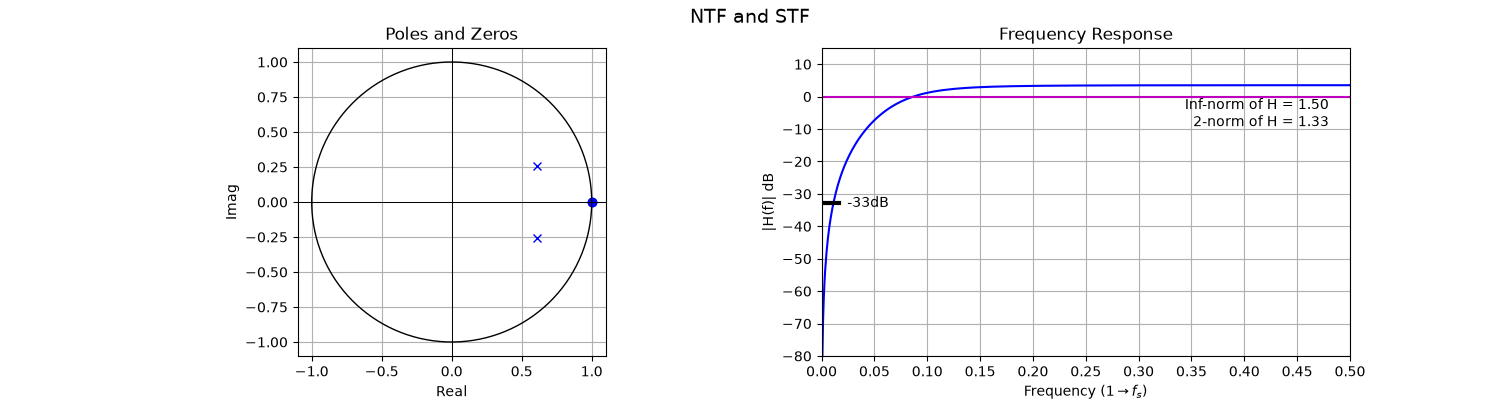

In [60]:
DocumentNTF(ABCD, osr, f0)
f = plt.gcf()
f.set_size_inches((15, 4))

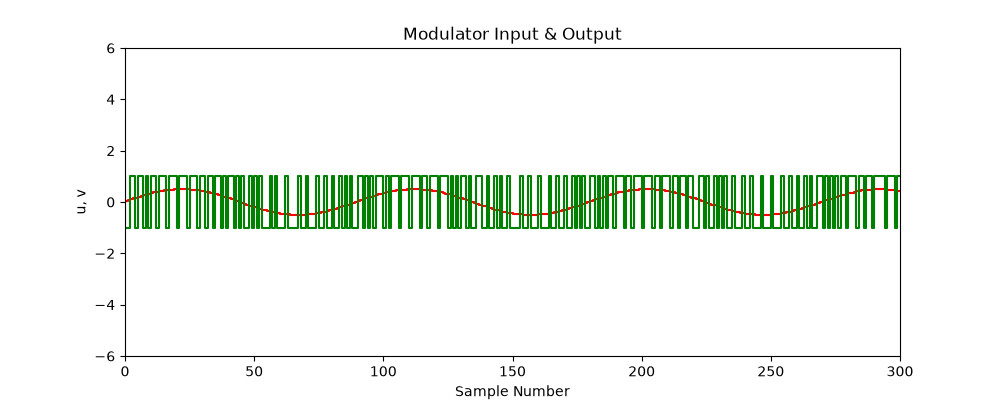

In [61]:
plt.figure(figsize=(10, 4))
N = 8192
fB = int(np.ceil(N/(2.*osr)))
ftest = np.floor(2./3.*fB)
u = 0.5*np.sin(2*np.pi*ftest/N*np.arange(N))
v, xn, xmax, y = simulateDSM(u, ABCD, nlev)
t = np.arange(301)
plt.step(t, u[t],'r')
plt.step(t, v[t], 'g')
plt.axis([0, 300, -6, 6])
plt.xlabel('Sample Number')
plt.ylabel('u, v')
plt.title('Modulator Input & Output');

## Typical spectral characteristics

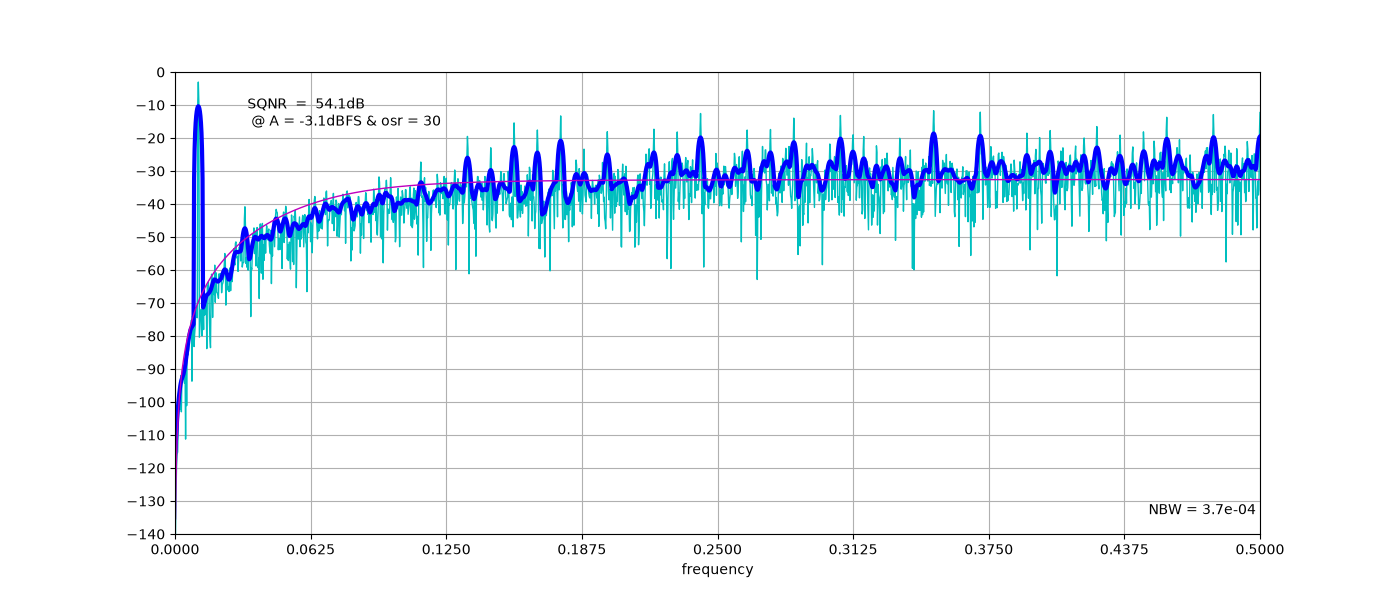

In [62]:
plt.figure(figsize=(14,6))
PlotExampleSpectrum(ntf, nlev-1, osr=osr, f0=f0)

## Signal to Noise Ratio analysis

In [63]:
snr, amp = simulateSNR(ntf, osr, None, f0, nlev)

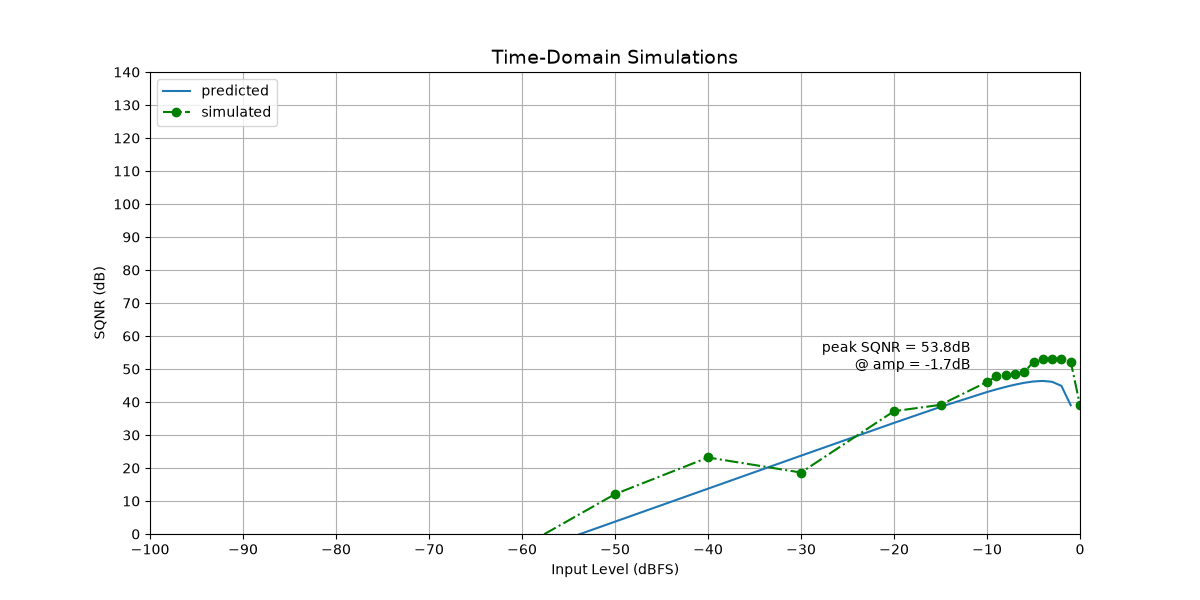

In [64]:
plt.figure(figsize=(12,6))
if nlev == 2:
    snr_pred, amp_pred, k0, k1, se = predictSNR(ntf, osr)
    plt.plot(amp_pred, snr_pred, '-', label='predicted')
plt.plot(amp, snr,'o-.g', label='simulated')
plt.xlabel('Input Level (dBFS)')
plt.ylabel('SQNR (dB)')

peak_snr, peak_amp = peakSNR(snr, amp)
if np.isfinite(peak_snr) and np.isfinite(peak_amp):
    msg = 'peak SQNR = %4.1fdB\n@ amp = %4.1fdB' % (peak_snr, peak_amp)
    plt.text(peak_amp - 10, peak_snr, msg,
             horizontalalignment='right', verticalalignment='center')
msg = 'peak SQNR = %4.1fdB  \n@ amp = %4.1fdB  ' % (peak_snr, peak_amp)
# plt.text(peak_amp-10,peak_snr,msg, horizontalalignment='right', verticalalignment='center')
# msg = 'OSR = %d ' % osr
figureMagic([-100, 0], 10, None, [0, 140], 10, None, (12, 6), 'Time-Domain Simulations')
plt.legend(loc=2)

## Dynamic range scaling xlim=0.25 (max INT output)

Keep the integrator outputs within their working range -- to avoid waveform clipping and instabilities.

The ABCD matrix is scaled opportunely, then the effectiveness of the dynamic range scaling is verified and the state maxima are plotted for different amplitudes.

In [65]:
print('Doing dynamic range scaling... ')
ABCD0 = ABCD.copy()
ABCD, umax, S = scaleABCD(ABCD0, nlev, f0, xlim=xlim)
print('Done.')
print("Maximum input magnitude: %.3f" % umax)

Doing dynamic range scaling... 
Done.
Maximum input magnitude: 0.967


In [66]:
print('ABCD Matrix before scaling')
print('')
print(ABCD0)
print('')
print('ABCD Matrix after scaling')
print('')
print(ABCD)

ABCD Matrix before scaling

[[ 1.    -0.     1.    -1.   ]
 [ 1.     1.     0.     0.   ]
 [ 0.775  0.216  1.     0.   ]]

ABCD Matrix after scaling

[[ 1.     0.     0.371 -0.371]
 [ 0.053  1.     0.     0.   ]
 [ 2.087 11.092  1.     0.   ]]


In [67]:
print('Verifying dynamic range scaling... ')
u = np.linspace(0, 0.95*umax, 30)
N = 1000
N0 = 50
test_tone = np.cos(2*np.pi*f0*np.arange(N))
test_tone[:N0] = test_tone[:N0]*(0.5 - 0.5*np.cos(2*np.pi/N0*np.arange(N0)))
maxima = np.zeros((order, u.shape[0]))
for i in np.arange(u.shape[0]):
    ui = u[i]
    v, xn, xmax, y = simulateDSM(ui*test_tone, ABCD, nlev)
    maxima[:, i] = xmax[:, 0]
    if (xmax > 100).any(): 
        print('Warning, umax from scaleABCD was too high.')
        umax = ui
        u = u[:i]
        maxima = maxima[:, :i]
        break
print('Done.')
print("Maximum DC input level: %.3f" % umax)

Verifying dynamic range scaling... 
Done.
Maximum DC input level: 0.967


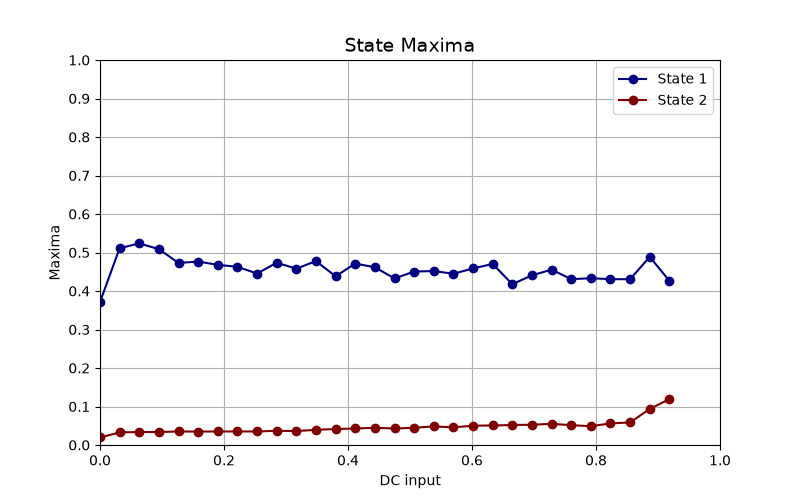

In [68]:
colors = plt.get_cmap('jet')(np.linspace(0, 1.0, order))
for i in range(order):
    plt.plot(u,maxima[i,:], 'o-', color=colors[i], label='State %d' % (i+1))
plt.grid(True)
#plt.text(umax/2, 0.05, 'DC input', horizontalalignment='center', verticalalignment='center')
figureMagic([0, 1], None, None, [0, 1] , 0.1, 2, [8, 5], 'State Maxima')
plt.xlabel('DC input')
plt.ylabel('Maxima')
plt.legend(loc='best');

## Conclusions
###Scaled coefficients

In [69]:
a, g, b, c = mapABCD(ABCD, form)
adc = {
       'order':order,
       'osr':osr,
       'nlev':nlev,
       'f0':f0,
       'ntf':ntf,
       'ABCD':ABCD,
       'umax':umax,
       'peak_snr':peak_snr,
       'form':form,
       'coefficients':{
                       'a':a,
                       'g':g,
                       'b':b,
                       'c':c
                      }
      }

### Final ADC coefficients

In [70]:
t = Table()
ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']
t.append(['Coefficients', 'A', 'G', 
          'B', 'C'])
t.append(['', 'a(n)', 'g(n)', ' b(n)', ' c(n)'])
[t.append(x) for x in zip_longest(ilabels, 
                                   adc['coefficients']['a'].tolist(), 
                                   adc['coefficients']['g'].tolist(), 
                                   adc['coefficients']['b'].tolist(), 
                                   adc['coefficients']['c'].tolist(), fillvalue="")]
t


Coefficients,A,G,B,C
,a(n),g(n),b(n),c(n)
#1,2.087,-0.000,0.371,0.371
#2,11.092,,0.000,0.053
#3,,,1.000,
#4,,,,
#5,,,,
#6,,,,


## Multiply Coeff by VREF 
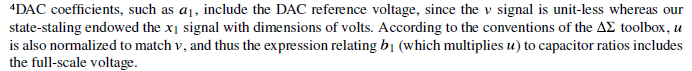
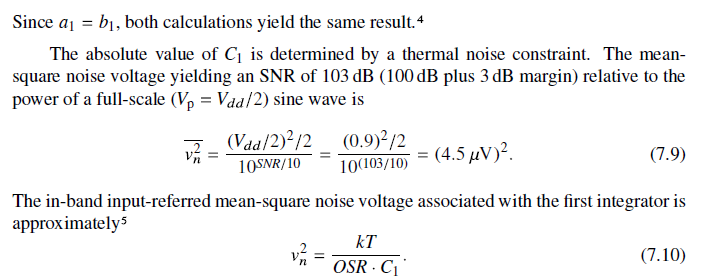 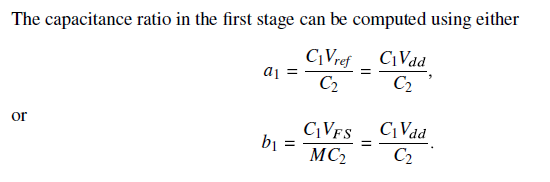

In [71]:
VDD = 1
Vref = VDD
VFS = 2*Vref
M = nlev-1
scaleCoef = Vref

#scaleCoef = VDD
adc_r = dict(adc)                  
adc_r['coefficients'] = {
    'a': adc['coefficients']['a']*scaleCoef,
    'g': adc['coefficients']['g']*scaleCoef,
    'b': adc['coefficients']['b']*scaleCoef,
    'c': adc['coefficients']['c'], #ON MULTIPLIE PAS LE C
}

print("Final ADC coefficients VDD scaled :")
print("  %s\n   %s" % ('a', adc_r['coefficients']['a']))
print("  %s\n   %s" % ('g', adc_r['coefficients']['g']))
print("  %s\n   %s" % ('b', adc_r['coefficients']['b']))
print("  %s\n   %s" % ('c', adc_r['coefficients']['c']))

Final ADC coefficients VDD scaled :
  a
   [ 2.087 11.092]
  g
   [-0.]
  b
   [0.371 0.    1.   ]
  c
   [0.371 0.053]


## Coefficient rouding into implementable CAPS

In [72]:
import math
from numbers import Integral, Real

FORMS = ('CRFB', 'CIFB', 'CRFF', 'CIFF')


def quantize_node(branches, max_surface=64, tol_pct=5.0):
    """Precision first, surface as tie-break; fallback outside tolerance."""
    if isinstance(max_surface, bool) or not isinstance(max_surface, Integral) or max_surface < 1:
        raise ValueError('max_surface must be a positive integer (Cu).')
    if not math.isfinite(tol_pct) or tol_pct < 0:
        raise ValueError('tol_pct must be finite and nonnegative.')
    if any(not math.isfinite(v) for v in branches.values()):
        raise ValueError('Nonfinite coefficient.')
    active = {n: v for n, v in branches.items() if v != 0}
    if not active:
        return None, {}
    valides, secours = [], []
    for D in range(1, int(max_surface) + 1):
        caps, err_max = {}, 0.0
        for name, val in active.items():
            Cx = round(abs(val) * D)
            if Cx == 0:
                break
            reel = math.copysign(Cx / D, val)
            err = abs(val - reel) / abs(val) * 100.0
            err_max = max(err_max, err)
            caps[name] = (Cx, reel, err)
        else:
            surf = D + sum(c for c, _, _ in caps.values())
            if surf <= max_surface:
                (valides if err_max <= tol_pct else secours).append(
                    (err_max, surf, D, caps))
    candidates = valides or secours
    if not candidates:
        return None, {}
    _, _, D, caps = min(candidates, key=lambda x: (x[0], x[1]))
    return D, caps


def _normalize(a, g, b, c, form):
    form = str(form).strip().upper()
    if form not in FORMS:
        raise ValueError(f'Unsupported form {form!r}; expected {FORMS}.')
    a, g, c = [list(map(float, v)) for v in (a, g, c)]
    b = [float(b)] if isinstance(b, Real) else list(map(float, b))
    n = len(a)
    if n < 1:
        raise ValueError('Order must be >= 1.')
    if len(b) == 1:
        b += [0.0] * n
    # An empty g vector means no local resonator feedback.
    if not g:
        g = [0.0] * (n // 2)
    if len(c) != n or len(b) != n + 1 or len(g) != n // 2:
        raise ValueError(f'Order {n}: expected len(a,c)={n}, len(b)={n+1}, len(g)={n//2}.')
    if any(not math.isfinite(x) for v in (a, g, b, c) for x in v):
        raise ValueError('All coefficients must be finite.')
    return a, g, b, c, form


def build_nodes(a, g, b, c, form='CRFB'):
    """Physical coefficient branches, NOT expanded ABCD matrix entries.

    Schreier / python-deltasigma coefficient convention.
    FB: ai feedback to integrator i; ci to integrator i+1 (cn to output).
    FF: ai to output; c1 DAC feedback to integrator 1; ci to integrator i.
    gj returns from the second stage of a resonator to its first stage.
    Output denominator is Cref/Csum, not an integration capacitor.
    Signs here are coefficient signs, as in the original function;
    structural negative feedback is applied by stuffABCD / circuit wiring.
    """
    a, g, b, c, form = _normalize(a, g, b, c, form)
    n = len(a)
    fb = form.endswith('FB')
    nodes = {}
    for i in range(n):
        branches = {f'b{i+1}': b[i]}
        if fb:
            branches[f'a{i+1}'] = a[i]
            if i:
                branches[f'c{i}'] = c[i-1]
        else:
            branches[f'c{i+1}'] = c[i]
        nodes[f'Integrateur {i+1}'] = branches
    # Odd order: standalone first integrator, then pairs (2,3), (4,5)...
    # Even order: pairs (1,2), (3,4)...
    for j, val in enumerate(g):
        first = n % 2 + 2*j  # zero-based index of first stage in pair
        nodes[f'Integrateur {first+1}'][f'g{j+1}'] = val
    output = {f'b{n+1}': b[n]}
    if fb:
        output[f'c{n}'] = c[-1]
    else:
        output.update({f'a{i+1}': a[i] for i in range(n)})
    nodes['Sortie/quantif'] = output
    return nodes


def coeffs_to_caps(adc, max_surface=64, tol_pct=5.0, ndigits=4,
                   form=None, verbose=True):
    """Return (resume, coeffs_maj), with arbitrary order and four forms.

    Explicit form overrides adc['form'] / adc['topology']; default CRFB.
    ndigits=None disables cleanup rounding. Budgets include denominator.
    Infeasible active nodes raise, rather than return unimplemented values.
    tol_pct=0 retains original fallback: it does NOT enforce exact ratios.
    """
    form = form if form is not None else adc.get('form', adc.get('topology', 'CRFB'))
    coef = adc['coefficients']
    a0, g0, b0, c0, form = _normalize(
        coef['a'], coef.get('g', []), coef['b'], coef['c'], form)
    raw = dict(zip(('a', 'g', 'b', 'c'), (a0, g0, b0, c0)))
    if ndigits is not None and (not isinstance(ndigits, Integral) or ndigits < 0):
        raise ValueError('ndigits must be None or a nonnegative integer.')
    target = {k: [round(x, ndigits) if ndigits is not None else x for x in v]
              for k, v in raw.items()}
    nodes = build_nodes(**target, form=form)
    nodes_raw = build_nodes(**raw, form=form)
    # Initialize with targets: coefficients rounded to zero stay zero.
    updated = {k: list(v) for k, v in target.items()}
    resume = {}
    log = print if verbose else lambda *args, **kwargs: None
    for k, v in target.items():
        log(f'{k} = {v}')
    log('rounding....\n')
    log('=== Caps implementables (unites de Cu) ===\n')
    for node, branches in nodes.items():
        budget = max_surface.get(node, 64) if isinstance(max_surface, dict) else max_surface
        tol = tol_pct.get(node, 5.0) if isinstance(tol_pct, dict) else tol_pct
        # Preserve the original display order without changing optimization.
        if node == 'Integrateur 1':
            priority = {'b': 0, 'a': 1, 'c': 2, 'g': 3}
        else:
            priority = {'c': 0, 'a': 1, 'g': 2, 'b': 3}
        branches = dict(sorted(branches.items(),
                               key=lambda item: (priority[item[0][0]], int(item[0][1:]))))
        D, caps = quantize_node(branches, budget, tol)
        if D is None:
            if any(v != 0 for v in branches.values()):
                raise ValueError(f'{node}: aucune solution sous {budget} Cu.')
            resume[node] = (None, {})
            log(f'{node}: aucune branche active.')
            continue
        err_max = max(e for _, _, e in caps.values())
        # Cint is retained as the historical display label, including output.
        # At the output this denominator represents the summing reference.
        etat = 'EXACT' if err_max <= 0.1 else f'approx (err_max={err_max:.2f}%)'
        log(f'{node} :  Cint = {D} Cu  (surface<={budget}, tol={tol}%, {etat})')
        for name, (Cx, reel, err) in caps.items():
            updated[name[0]][int(name[1:])-1] = reel
            entree = nodes_raw[node][name]
            log(f'    {name:3s}  {entree:+9.6f}  ->  {Cx:>2d} Cu'
                f'   ratio {Cx}/{D} err={err:5.2f}%')
        total = D + sum(Cx for Cx, _, _ in caps.values())
        log(f'    surface du noeud = {total} Cu\n')
        resume[node] = (D, caps)
    log('=== Coefficients mis a jour (ratios implementes) ===')
    for k, v in updated.items():
        log(f'  {k} = {[round(x, 6) for x in v]}')
    return resume, updated


resume, coeffs_maj = coeffs_to_caps(adc_r, form=form, max_surface=40, tol_pct=0.0)

a = [2.0867, 11.0919]
g = [-0.0]
b = [0.3713, 0.0, 1.0]
c = [0.3713, 0.0525]
rounding....

=== Caps implementables (unites de Cu) ===

Integrateur 1 :  Cint = 19 Cu  (surface<=40, tol=0.0%, approx (err_max=0.78%))
    b1   +0.371321  ->   7 Cu   ratio 7/19 err= 0.78%
    c1   +0.371321  ->   7 Cu   ratio 7/19 err= 0.78%
    surface du noeud = 33 Cu

Integrateur 2 :  Cint = 19 Cu  (surface<=40, tol=0.0%, approx (err_max=0.25%))
    c2   +0.052534  ->   1 Cu   ratio 1/19 err= 0.25%
    surface du noeud = 20 Cu

Sortie/quantif :  Cint = 1 Cu  (surface<=40, tol=0.0%, approx (err_max=4.15%))
    a1   +2.086742  ->   2 Cu   ratio 2/1 err= 4.15%
    a2   +11.091892  ->  11 Cu   ratio 11/1 err= 0.83%
    b3   +1.000000  ->   1 Cu   ratio 1/1 err= 0.00%
    surface du noeud = 15 Cu

=== Coefficients mis a jour (ratios implementes) ===
  a = [2.0, 11.0]
  g = [-0.0]
  b = [0.368421, 0.0, 1.0]
  c = [0.368421, 0.052632]


In [73]:
a_r = coeffs_maj['a']
g_r = coeffs_maj['g']
b_r = coeffs_maj['b']
c_r = coeffs_maj['c']
ABCD_r = stuffABCD(a_r, g_r, b_r, c_r, form)

### FFT CHECK AND MAX AMPLITUDE WITH ROUNDING COEFF

ABCD Matrix:
[[ 1.     0.     0.368 -0.368]
 [ 0.053  1.     0.     0.   ]
 [ 2.    11.     1.     0.   ]]


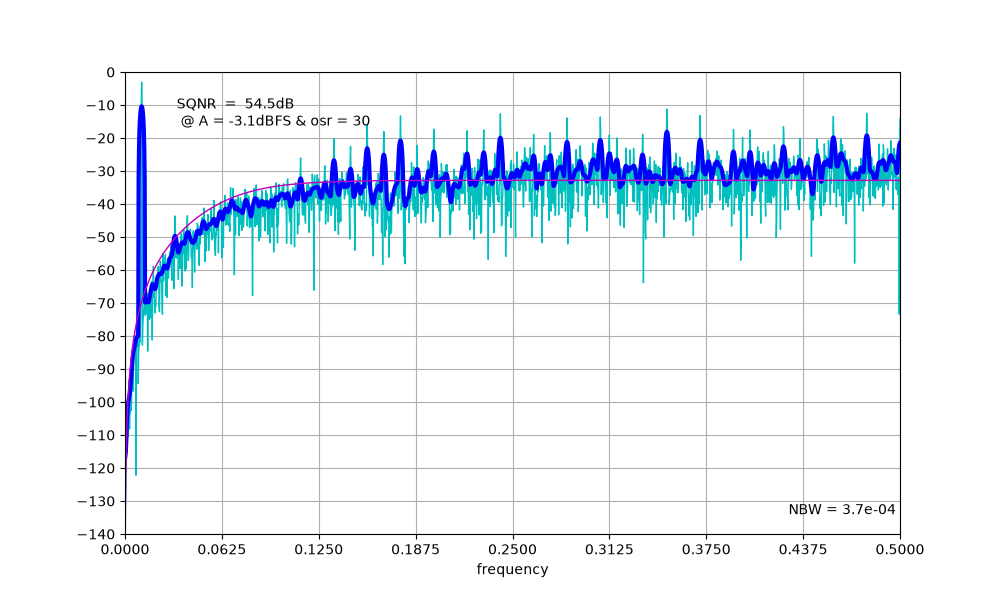

In [74]:
print("ABCD Matrix:")
print(ABCD_r)
[ntf_r,stf_r] = calculateTF(ABCD_r)
plt.figure(figsize=(10,6))
PlotExampleSpectrum(ntf_r, nlev-1, osr=osr, f0=f0)

In [75]:
snr_r, amp_r = simulateSNR(ntf_r, osr, None, f0, nlev)

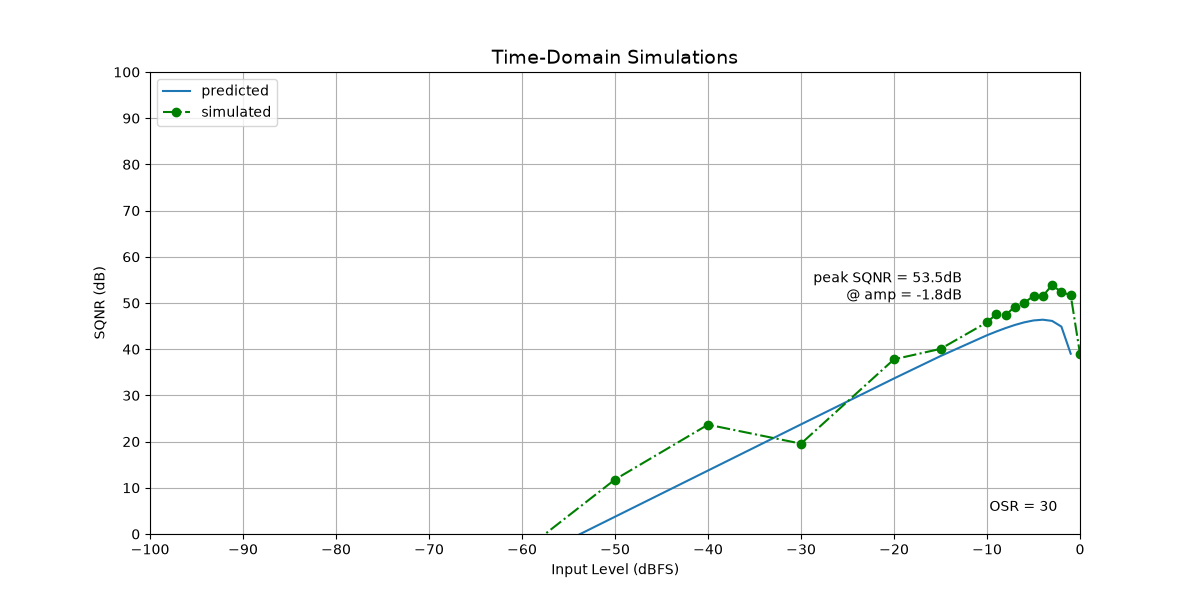

In [76]:
plt.figure(figsize=(15,8))
if nlev == 2:
    snr_pred, amp_pred, k0, k1, se = predictSNR(ntf, osr)
    plt.plot(amp_pred, snr_pred, '-', label='predicted')
plt.plot(amp_r, snr_r,'o-.g', label='simulated')
plt.xlabel('Input Level (dBFS)')
plt.ylabel('SQNR (dB)')
peak_snr, peak_amp = peakSNR(snr_r, amp_r)
msg = 'peak SQNR = %4.1fdB  \n@ amp = %4.1fdB  ' % (peak_snr, peak_amp)
plt.text(peak_amp-10,peak_snr,msg, horizontalalignment='right', verticalalignment='center');
msg = 'OSR = %d ' % osr
plt.text(-2, 5, msg, horizontalalignment='right');
figureMagic([-100, 0], 10, None, [0, 100], 10, None, [12, 6], 'Time-Domain Simulations')
plt.legend(loc=2);

## Absolute cap size
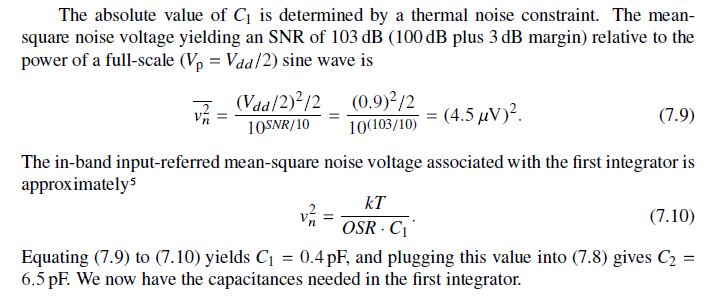

In [77]:
# #Compute capacitor sizes
# Vdd = 1
# Vref = 1
# FullScale = Vref * 2
# #M = nlev-1
# DR = 72 # Dynamic range in dB, plus 3-dB margin
# k = 1.38e-23
# T = 300
# kT = k*T
# #First stage values based on kT/C noise
# v_n2 = (FullScale/2)**2/2 / undbp(DR); # = kT/(osr*C1)
# C1 = kT/(osr*v_n2)
# ##Add factor for incremental
# print(C1*1e15, 'fF')
# print(np.sqrt(v_n2))

In [78]:
"""
sd_model.py - Modulateur Sigma-Delta (matrice ABCD de Schreier) avec non-idealites par ampli
=============================================================================================

Conventions (identiques a la Delta-Sigma Toolbox de R. Schreier)
    x(n+1) = A x(n) + B1 u(n) + B2 v(n)          ABCD = [[A , B1, B2],
    y(n)   = C x(n) + D1 u(n)         (D2 = 0)          [C , D1, D2]]
    v(n)   = Q(y(n))                  quantificateur nlev niveaux

Passage en volts
    Les signaux "normalises" de la toolbox ont des niveaux DAC espaces de 2 et un
    full-scale de +-(nlev-1).  Ici tout est calcule en VOLTS avec  s = vref/(nlev-1) :
        x_V = s*x_norm ,  u_V = s*u_norm ,  v_V = s*v_norm      (ABCD inchange, lineaire)
    Niveaux DAC : multiples de 2*s (nlev impair : 0,+-2s,..  /  nlev pair : +-s,+-3s,..),
    donc |v| <= vref.

ENTREE : la matrice ABCD est fournie par l'utilisateur (SigmaDeltaModulator.from_abcd) et n'est jamais
modifiee.

Non-idealites, une par ampli (= une par etat/integrateur)
    gain_db   gain DC A0 de l'OTA -> fuite  alpha = 1/(1+1/(A0*beta))  (pole de z=1 vers alpha)
              et erreur de gain (meme facteur) :  x_i(n+1) = alpha_i * (A x + B w)_i
    vsat      saturation de sortie [V] (ecretage de l'etat, dur ou tanh).
              Par defaut vsat = VDD - headroom (swing differentiel crete ; /2 si single-ended)
    noise_rms bruit [V rms] ajoute A LA SORTIE de l'integrateur a chaque cycle d'integration
              (echantillon gaussien blanc, injecte avant saturation, puis integre par la memoire
              de l'etat).  C'est la forme "sortie" du kT/C + bruit ampli apres transfert de
              charge (Brigati et al., IEEE TCAS-I 2003).  Voir ktc_sigma_out().
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from typing import List, Optional

import numpy as np
from scipy import signal

K_B = 1.380649e-23  # J/K


# ----------------------------------------------------------------------------------------
# 1. Utilitaires ABCD (l'ABCD est FOURNIE par l'utilisateur ; aucune synthese ici)
# ----------------------------------------------------------------------------------------
def split_abcd(ABCD):
    ABCD = np.asarray(ABCD, float)
    N = ABCD.shape[0] - 1
    assert ABCD.shape == (N + 1, N + 2)
    assert abs(ABCD[N, N + 1]) < 1e-14, "D2 != 0 : boucle sans retard non supportee"
    return ABCD[:N, :N], ABCD[:N, N], ABCD[:N, N + 1], ABCD[N, :N], float(ABCD[N, N])



# ----------------------------------------------------------------------------------------
# 2. Coeur de simulation
# ----------------------------------------------------------------------------------------
def _core(A, B1, B2, C, D1, u, nlev, s, alpha, sig, vsat, soft, noise):
    """Boucle temporelle.  Tout en volts (s = volts par unite normalisee).
    Renvoie xs (N,n) [etat a l'instant de quantification], v (N), y (N), nclip (n)."""
    n = len(C)
    N = len(u)
    Ae = alpha[:, None] * A
    B1e = alpha * B1
    B2e = alpha * B2
    xs = np.empty((N, n))
    vv = np.empty(N)
    yy = np.empty(N)
    nclip = np.zeros(n)
    x = np.zeros(n)
    odd = nlev % 2 == 1
    qmax = nlev - 1
    finite = np.isfinite(vsat)
    for i in range(N):
        ui = u[i]
        y = float(C @ x) + D1 * ui
        yn = y / s
        q = 2 * math.floor((yn + 1) * 0.5) if odd else 2 * math.floor(yn * 0.5) + 1
        q = qmax if q > qmax else (-qmax if q < -qmax else q)
        v = q * s
        xs[i] = x
        vv[i] = v
        yy[i] = y
        x = Ae @ x + B1e * ui + B2e * v + noise[i]
        if finite.any():
            over = np.abs(x) > vsat
            nclip += over
            if soft:
                x = np.where(finite, vsat * np.tanh(x / np.where(finite, vsat, 1.0)), x)
            else:
                x = np.clip(x, -vsat, vsat)
    return xs, vv, yy, nclip


# ----------------------------------------------------------------------------------------
# 3. Description des amplis et du modulateur
# ----------------------------------------------------------------------------------------
@dataclass
class Amp:
    """Non-idealites d'UN ampli (integrateur).  Valeurs par defaut = ampli ideal."""
    gain_db: float = np.inf      # gain DC de l'OTA [dB]  (inf = ideal)
    beta: float = 0.5            # facteur de retroaction Cf/(Cf+Cs+Cp)
    vsat: Optional[float] = None  # saturation de sortie [V] ; None -> VDD - headroom
    headroom: float = 0.0        # [V] marge de sortie (Vdsat..) si vsat=None
    noise_rms: float = 0.0       # [V rms] bruit ajoute en sortie a chaque cycle

    @property
    def A0(self):
        return np.inf if np.isinf(self.gain_db) else 10 ** (self.gain_db / 20)

    @property
    def alpha(self):
        return 1.0 if np.isinf(self.gain_db) else 1.0 / (1.0 + 1.0 / (self.A0 * self.beta))


def ktc_sigma_out(cs: float, cf: float, T: float = 300.0, n_branches: int = 2,
                  vn_amp_in: float = 0.0) -> float:
    """Bruit [V rms] a la sortie d'un integrateur SC par cycle : (Cs/Cf)*sqrt(n*kT/Cs + vn^2).
    n_branches = 2 pour une branche signal + une branche DAC ; vn_amp_in = bruit ampli ramene
    a l'entree et echantillonne [V rms]."""
    return (cs / cf) * math.sqrt(n_branches * K_B * T / cs + vn_amp_in ** 2)


@dataclass
class SimResult:
    u: np.ndarray
    v: np.ndarray
    x: np.ndarray
    y: np.ndarray
    nclip_frac: np.ndarray
    k: int
    fin: float
    amp_v: float


class SigmaDeltaModulator:
    def __init__(self, ABCD, nlev: int, vref: float, vdd: float, osr: float, fB: float,
                 amps: Optional[List[Amp]] = None, differential: bool = True,
                 soft_sat: bool = False, name: str = "Sigma-Delta"):
        self.A, self.B1, self.B2, self.C, self.D1 = split_abcd(ABCD)
        self.order = len(self.C)
        self.nlev, self.vref, self.vdd = int(nlev), float(vref), float(vdd)
        self.osr, self.fB = float(osr), float(fB)
        self.fs = 2 * self.osr * self.fB
        self.amps = amps if amps is not None else [Amp() for _ in range(self.order)]
        assert len(self.amps) == self.order
        self.differential, self.soft_sat, self.name = differential, soft_sat, name

    # ---- construction ---------------------------------------------------------------
    @classmethod
    def from_abcd(cls, ABCD, nlev, vref, vdd, osr, fB, amps=None, differential=True,
                  soft_sat=False, name="Sigma-Delta"):
        """ABCD : matrice (N+1)x(N+2) [[A B1 B2],[C D1 D2]] fournie par l'utilisateur, utilisee TELLE QUELLE
        (aucun re-scaling). Convention Schreier : niveaux DAC normalises espaces de 2 (+-(nlev-1)),
        D2 = 0. ABCD peut etre un ndarray, une liste, ou un chemin .npy/.csv/.txt."""
        if isinstance(ABCD, str):
            ABCD = np.load(ABCD) if ABCD.endswith(".npy") else np.loadtxt(ABCD, delimiter="," if ABCD.endswith(".csv") else None)
        return cls(ABCD, nlev, vref, vdd, osr, fB, amps, differential, soft_sat, name)

    # ---- parametres derives ---------------------------------------------------------
    @property
    def s(self):
        return self.vref / (self.nlev - 1)

    def vsat_vec(self):
        out = []
        for a in self.amps:
            if a.vsat is not None:
                out.append(a.vsat)
            else:
                out.append((self.vdd - a.headroom) * (1.0 if self.differential else 0.5))
        return np.array(out, float)

    def alpha_vec(self):
        return np.array([a.alpha for a in self.amps])

    def noise_vec(self):
        return np.array([a.noise_rms for a in self.amps])

    # ---- simulation -----------------------------------------------------------------
    def make_input(self, N, fin=None, amp_dbfs=-5.0):
        if fin is None:
            fin = self.fB / 3
        k = max(3, int(round(fin * N / self.fs)) | 1)        # nb de periodes entier et impair
        amp_v = self.vref * 10 ** (amp_dbfs / 20)
        return k, k * self.fs / N, amp_v

    def simulate(self, N=2 ** 16, fin=None, amp_dbfs=-5.0, seed=0, ideal=False, n_discard=2048):
        k, fin_c, amp_v = self.make_input(N, fin, amp_dbfs)
        n = np.arange(N + n_discard)
        u = amp_v * np.sin(2 * np.pi * k * n / N)
        if ideal:
            alpha, sig, vs = np.ones(self.order), np.zeros(self.order), np.full(self.order, np.inf)
        else:
            alpha, sig, vs = self.alpha_vec(), self.noise_vec(), self.vsat_vec()
        noise = np.random.default_rng(seed).standard_normal((len(u), self.order)) * sig
        xs, v, y, ncl = _core(self.A, self.B1, self.B2, self.C, self.D1, u, self.nlev, self.s,
                              alpha, sig, vs, self.soft_sat, noise)
        return SimResult(u[n_discard:], v[n_discard:], xs[n_discard:], y[n_discard:],
                         ncl / len(u), k, fin_c, amp_v)

    # ---- analyse --------------------------------------------------------------------
    def analyze(self, res: SimResult):
        N = len(res.v)
        P = _power_spectrum(res.v)
        kb = int(N / (2 * self.osr))
        k = res.k
        ps = P[k - 1:k + 2].sum()
        mask = np.zeros(len(P), bool)
        mask[3:kb + 1] = True
        mask[k - 1:k + 2] = False
        pn = P[mask].sum()
        locked = ps <= 1e-30            # sortie constante (integrateur sature a 100 %) : modulateur bloque
        snr = -np.inf if locked else (np.inf if pn <= 1e-30 else 10 * np.log10(ps / pn))
        vs = self.vsat_vec()
        xmax = np.max(np.abs(res.x), axis=0)
        return dict(
            snr=snr, enob=(snr - 1.76) / 6.02, locked=locked, p_sig=ps, p_noise=pn,
            x_rms=np.sqrt(np.mean(res.x ** 2, axis=0)), x_max=xmax, vsat=vs,
            margin_db=20 * np.log10(vs / xmax), nclip_frac=res.nclip_frac,
            levels_used=len(np.unique(np.round(res.v / self.s))), kb=kb)

    # ---- rapport --------------------------------------------------------------------
    def report(self, res: SimResult, met=None, savepath=None, title=None, show_header=True):
        met = met or self.analyze(res)
        if show_header:
            print(self.header(res, met))
        return plot_report(self, res, met, savepath, title)

    def header(self, res, met):
        bits = math.ceil(math.log2(self.nlev))
        vs = self.vsat_vec()
        vs_s = "[" + ", ".join(f"{v:g}" for v in vs) + "]"
        L = [f"DAC: nlev={self.nlev} ({bits} bits)  vref={self.vref:g}  VDD={self.vdd:g}  VSAT={vs_s}",
             f"OSR={self.osr:g}  fin={res.fin:.1f} Hz  fB={self.fB:.1f} Hz  fs={self.fs / 1e3:.1f} kHz",
             f"niveaux DAC utilises: {met['levels_used']} / {self.nlev}",
             f"SNR = {met['snr']:.2f} dB   ENOB = {met['enob']:.2f} bits"
             + ("   [MODULATEUR BLOQUE : sortie constante]" if met["locked"] else "")]
        for i in range(self.order):
            a = self.amps[i]
            extra = []
            if not np.isinf(a.gain_db):
                extra.append(f"A0={a.gain_db:g}dB")
            if a.noise_rms > 0:
                extra.append(f"bruit={a.noise_rms * 1e6:.1f}uVrms")
            if met["nclip_frac"][i] > 0:
                extra.append(f"CLIP={100 * met['nclip_frac'][i]:.2f}%")
            L.append(f"  INT{i + 1}: rms={met['x_rms'][i]:.4f}  max|o|={met['x_max'][i]:.4f}  "
                     f"VSAT={vs[i]:g}  marge={met['margin_db'][i]:.1f} dB"
                     + ("   " + " ".join(extra) if extra else ""))
        return "\n".join(L)


# ----------------------------------------------------------------------------------------
# 4. Utilitaires d'analyse spectrale / graphiques
# ----------------------------------------------------------------------------------------
def _power_spectrum(v):
    """Spectre unilateral en puissance (V^2 par bin), fenetre de Hann, normalise Parseval :
    sinusoide d'amplitude A coherente -> somme des 3 bins centraux = A^2/2."""
    N = len(v)
    w = signal.windows.hann(N, sym=False)
    X = np.fft.rfft(v * w)
    P = 2 * np.abs(X) ** 2 / (N * np.sum(w ** 2))
    P[0] /= 2
    return P


COLORS = ["#3a6fb0", "#3fa34d", "#c0504d", "#8e5ea2", "#e1a21b", "#2aa5b5"]


def plot_report(mod: SigmaDeltaModulator, res: SimResult, met, savepath=None, title=None):
    import sys
    import matplotlib
    if "ipykernel" not in sys.modules:      # script : pas de fenetre ; Jupyter : on garde le backend inline
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    N = len(res.v)
    P = _power_spectrum(res.v)
    pdb = 10 * np.log10(P / (mod.vref ** 2 / 2) + 1e-30)
    f = np.arange(N // 2 + 1) * mod.fs / N
    n = mod.order
    fig = plt.figure(figsize=(10.2, 7.6))
    gs = fig.add_gridspec(2, n, height_ratios=[1.65, 1], hspace=0.38, wspace=0.32)
    ax = fig.add_subplot(gs[0, :])
    ax.semilogx(f[1:], pdb[1:], color="0.25", lw=0.5, label="FFT (Hann)")
    ax.axvline(mod.fB, color="darkred", ls="--", lw=1.0, label=f"Bande fB = {mod.fB / 1e3:.1f} kHz")
    ax.set_xlim(f[1], mod.fs / 2)
    ax.set_ylim(-160, 5)
    ax.grid(True, which="both", ls=":", lw=0.5)
    ax.set_xlabel("Frequence (Hz)")
    ax.set_ylabel("PSD (dB)")
    bits = math.ceil(math.log2(mod.nlev))
    ax.set_title(title or (f"{mod.name} multibit+sat - nlev={mod.nlev} ({bits} bits) vref={mod.vref:g} | "
                           f"OSR={mod.osr:g}  SNR={met['snr']:.1f} dB  ENOB={met['enob']:.2f} bits"),
                 fontsize=10)
    ax.legend(loc="lower left", fontsize=8)
    vs = mod.vsat_vec()
    for i in range(n):
        a = fig.add_subplot(gs[1, i])
        xi = res.x[:, i]
        col = COLORS[i % len(COLORS)]
        a.hist(xi, bins=100, density=True, color=col, alpha=0.9)
        lim = 1.2 * met["x_max"][i]
        if vs[i] < 3 * met["x_max"][i]:
            lim = max(lim, 1.1 * vs[i])
        a.set_xlim(-lim, lim)
        a.axvline(vs[i], color="k", ls="--", lw=1.0, label=f"VSAT = {vs[i]:g}")
        a.axvline(-vs[i], color="k", ls="--", lw=1.0)
        a.set_title(f"INT{i + 1}  (o{i + 1})  rms={met['x_rms'][i]:.3f} max={met['x_max'][i]:.3f}",
                    fontsize=8.5)
        a.set_xlabel("sortie integrateur (V)", fontsize=8)
        if i == 0:
            a.set_ylabel("densite", fontsize=8)
        a.tick_params(labelsize=7)
        a.grid(True, ls=":", lw=0.5)
        a.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Sigma-Delta {form} ordre {n} : spectre et occupation des etats internes", fontsize=10.5)
    if savepath:
        fig.savefig(savepath, dpi=130, bbox_inches="tight")
    return fig

DAC: nlev=2 (1 bits)  vref=1  VDD=1  VSAT=[1, 1]
OSR=30  fin=5569.5 Hz  fB=16666.7 Hz  fs=1000.0 kHz
niveaux DAC utilises: 2 / 2
SNR = 54.29 dB   ENOB = 8.73 bits
  INT1: rms=0.2209  max|o|=0.5403  VSAT=1  marge=5.3 dB   A0=60dB
  INT2: rms=0.0196  max|o|=0.0548  VSAT=1  marge=25.2 dB   A0=60dB


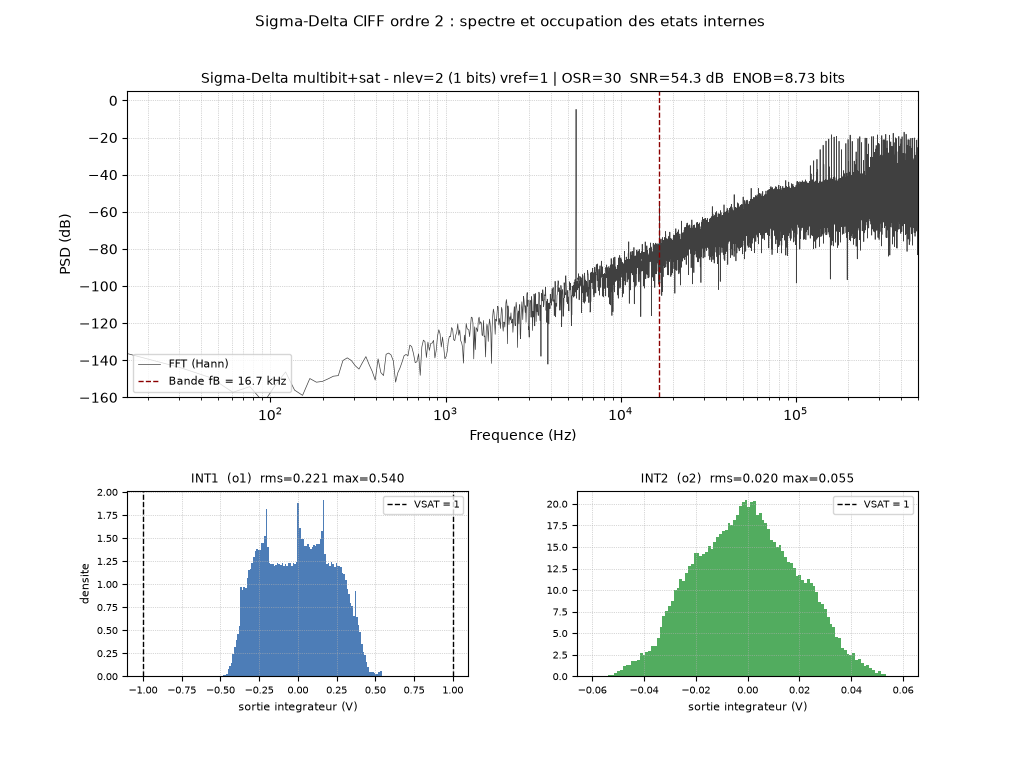

In [79]:
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

# ======================= A MODIFIER =======================
ABCD = ABCD_r   # ou votre np.array([...]) / np.load("abcd.npy")
NLEV, VREF, VDD, OSR, FB = nlev, Vref, Vdd, osr, 16666.7    # FB = bande du signal (Hz) -> fs = 2*OSR*FB
FIN, AMP_DBFS, N = 5554.2, -3, 2**16                 # entree sinus : frequence, amplitude (dBFS), nb d'echantillons

# une ligne par integrateur : gain_db (inf = ideal), noise_rms [V rms], vsat [V] (None -> VDD - headroom)
AMPS = [Amp(gain_db=60, noise_rms=00e-6),
        Amp(gain_db=60, noise_rms=00e-6)]
# AMPS = None   # <- modulateur ideal
# ==========================================================

m = SigmaDeltaModulator.from_abcd(ABCD, NLEV, VREF, VDD, OSR, FB, amps=AMPS)
res = m.simulate(N=N, fin=FIN, amp_dbfs=AMP_DBFS)
fig = m.report(res)          # affiche l'en-tete texte et construit la figure
display(fig); plt.close(fig)